# 15. Shifting Periodic Layers Sideways: Shear Transformations

## Physical Motivation & Learning Objectives
Shifting a periodic layer sideways by $\Delta x$ only multiplies each of its plane-wave diffraction orders by a phase:
$$e_m(x - \Delta x, y) = e_m(x, y) \exp(-i k_{x, m} \Delta x)$$
EMUstack therefore applies lateral shifts between layers with the `shears` argument of `Stack`, without re-solving any layer's modes.
In this tutorial:
1. We stack two different 1D gratings with period 760 nm: a 150 nm-thick grating with two inclusions per period, and a 2.9 µm-thick grating with one.
2. We shift the layers sideways by fixed fractions of the period, `shears=[(0.1, 0.0), (-0.3, 0.1), (0.2, 0.5)]`; only the differences between neighbouring entries matter.
3. We compute T, R and A at $\lambda = 1600$ nm for incidence angles from 0° to 20°.


**Legacy example.** This notebook reproduces `simo_060-shear_transformations.py` from the original EMUstack. The `LEGACY_PARAMS` switch in the next cell selects the inputs:

- `LEGACY_PARAMS = True`: the legacy inputs, unchanged. Both legacy EMUstack and the ported solver stop on these inputs: the grating mesh (`lc_bkg = 0.1`) has fewer unknowns than 60 Bloch modes need.
- `LEGACY_PARAMS = False` *(default)*: a 10x finer grating mesh (`lc_bkg = 0.01`). The two touching gratings are numerically ill-conditioned: in both codes energy is conserved only to about 0.5% (the stack is lossless), and the two codes agree to 6e-3.

In [ ]:
# True: the inputs of the original EMUstack example, unchanged.
# False: same structure, a 10x finer grating mesh (lc_bkg 0.01).
LEGACY_PARAMS = False


##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



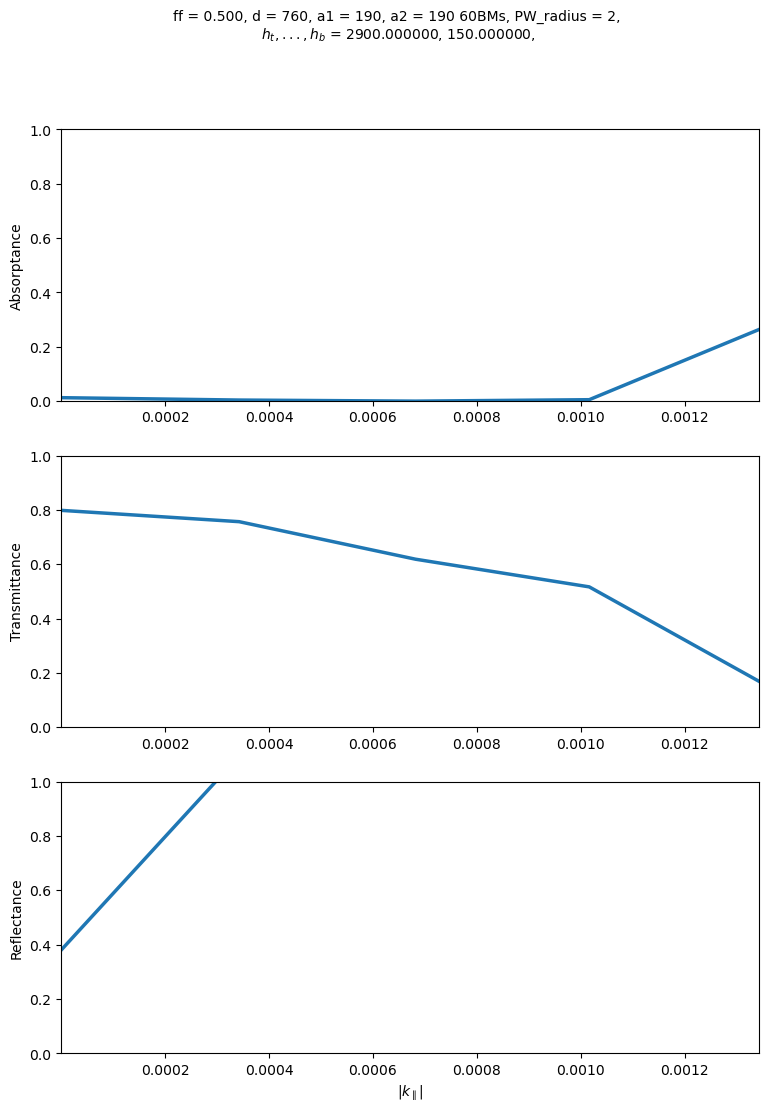

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack

azi_angles = np.linspace(0.0, 20.0, 5)
wl = 1600.0
period = 760.0
lc_bkg = 0.1 if LEGACY_PARAMS else 0.01

light_list = [objects.Light(wl, max_order_PWs=2, theta=p, phi=0.0) for p in azi_angles]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)

grating_1 = objects.NanoStruct(
    '1D_array', period, small_space=period/2.0,
    diameter1=int(round(0.25*period)), diameter2=int(round(0.25*period)),
    height_nm=150.0, inclusion_a=materials.Material(3.61 + 0.0j),
    inclusion_b=materials.Material(3.61 + 0.0j), background=materials.Material(1.46 + 0.0j),
    loss=True, make_mesh_now=True, force_mesh=False, lc_bkg=lc_bkg, lc2=3.0
)

grating_2 = objects.NanoStruct(
    '1D_array', period, int(round(0.75*period)),
    height_nm=2900.0, background=materials.Material(1.46 + 0.0j),
    inclusion_a=materials.Material(3.61 + 0.0j),
    loss=True, make_mesh_now=True, force_mesh=False, lc_bkg=lc_bkg, lc2=3.0
)

num_BMs = 60

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_g1  = grating_1.calc_modes(light, num_BMs=num_BMs)
    sim_g2  = grating_2.calc_modes(light, num_BMs=num_BMs)
    stk = Stack((sim_sub, sim_g1, sim_g2, sim_sup), shears=[(0.1, 0.0), (-0.3, 0.1), (0.2, 0.5)])
    stk.calc_scat(pol='TE')
    return stk

stacks_list = [simulate_stack(l) for l in light_list]

figs_tra = plotting.t_r_a_plots(stacks_list)
plt.show()


## Layer Setup: Two 1D Gratings


## Sweeping the Incidence Angle with Fixed Shears


## Physical Interpretation
- The stack is lossless, so $T + R = 1$; with the default (fine) mesh this holds to within 0.5%.
- $T$ rises from 0.79 at normal incidence to 0.98 at 15° and drops to 0.40 at 20°. Only five angles are computed, so the curve between them is not resolved.
- Changing `shears` changes the spectra without recomputing any Bloch modes: only the interface matrices pick up phases.
